# Load test dataset and model

In [19]:
# ============================================================
# PQD-16c SHAP NOTEBOOK
# CELL 1 — LOAD MODEL + TEST DATA
# ============================================================

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


# ============================================================
# PROJECT PATH
# ============================================================

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "scripts").exists():
    PROJECT_ROOT = Path.cwd().parent

sys.path.insert(
    0,
    str(PROJECT_ROOT / "scripts")
)


# ============================================================
# IMPORT OUR SHAP LIBRARY
# ============================================================

import shap_cnn_bilstm as shap_lib


# ============================================================
# CONFIGURATION
# ============================================================

MODEL_PATH = (
    PROJECT_ROOT
    / "models"
    / "cnn_res_bilstm_pq.pth"
)

DATA_DIR = (
    PROJECT_ROOT
    / "dataset"
    / "PQD-16c-Data"
)

TEST_PATH = DATA_DIR / "test.csv"


# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("=" * 70)
print("PQD-16c CNN-RES-BiLSTM SHAP ANALYSIS")
print("=" * 70)
print(f"Device : {DEVICE}")
print(f"Model  : {MODEL_PATH}")
print(f"Test   : {TEST_PATH}")
print("=" * 70)


# ============================================================
# LOAD CHECKPOINT
# ============================================================

checkpoint = shap_lib.load_checkpoint(
    MODEL_PATH,
    DEVICE
)

NUM_CLASSES = int(
    checkpoint.get(
        "num_classes",
        16
    )
)


# ============================================================
# LOAD METADATA
# ============================================================

(
    CLASS_NAMES,
    TRAIN_MEAN,
    TRAIN_STD
) = shap_lib.get_dataset_metadata(
    pd,
    DATA_DIR,
    checkpoint
)

print("\nClasses:")
for i, name in enumerate(CLASS_NAMES):
    print(f"  {i:2d} -> {name}")

print("\nNormalization:")
print(f"  Mean : {TRAIN_MEAN:.6f}")
print(f"  Std  : {TRAIN_STD:.6f}")


# ============================================================
# BUILD MODEL
# ============================================================

model = shap_lib.build_model(
    shap_lib.import_runtime()[0],
    NUM_CLASSES
).to(DEVICE)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()


# ============================================================
# LOAD TEST DATASET
# ============================================================

(
    TEST_SIGNALS,
    TEST_RAW_SIGNALS,
    TEST_LABELS,
    SIGNAL_COLUMNS
) = shap_lib.load_dataset(
    pd,
    TEST_PATH,
    TRAIN_MEAN,
    TRAIN_STD
)


# ============================================================
# BASIC DATASET INFORMATION
# ============================================================

print("\n" + "=" * 70)
print("TEST DATASET")
print("=" * 70)

print(f"Samples       : {len(TEST_SIGNALS)}")
print(f"Signal points : {TEST_SIGNALS.shape[-1]}")
print(f"Shape         : {tuple(TEST_SIGNALS.shape)}")

print("\nDataset loaded successfully.")
print("=" * 70)

PQD-16c CNN-RES-BiLSTM SHAP ANALYSIS
Device : cpu
Model  : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/models/cnn_res_bilstm_pq.pth
Test   : /mnt/ntfs/my_docs/VIT_Y4_SEM7/C1_XAI/project/dataset/PQD-16c-Data/test.csv

Checkpoint does not contain 'class_names'.
Recomputing from train.csv...

Checkpoint does not contain training normalization values.
Recomputing from train.csv...

Classes:
   0 -> Flicker
   1 -> Flicker+Harmonics
   2 -> Flicker+Sag
   3 -> Flicker+Swell
   4 -> Harmonics
   5 -> Impulsive Transient
   6 -> Interruption
   7 -> Interruption+Harmonics
   8 -> Normal
   9 -> Notch
  10 -> Oscillatory transient
  11 -> Sag
  12 -> Sag+Harmonics
  13 -> Spike
  14 -> Swell
  15 -> Swell+Harmonics

Normalization:
  Mean : 0.000172
  Std  : 0.711352

TEST DATASET
Samples       : 320
Signal points : 640
Shape         : (320, 1, 640)

Dataset loaded successfully.


# Select a Sample

In [24]:
# ============================================================
# PQD-16c NOTEBOOK
# CELL 1.5 — SELECT TEST SAMPLE
# ============================================================

while True:

    choice = input(
        "Analyze a random sample or choose one? [random/sample]: "
    ).strip().lower()

    # --------------------------------------------------------
    # RANDOM SAMPLE
    # --------------------------------------------------------

    if choice == "random":

        sample_idx = np.random.randint(
            0,
            len(TEST_SIGNALS)
        )

        print(
            f"\nRandomly selected sample: "
            f"{sample_idx + 1}"
        )

        break

    # --------------------------------------------------------
    # MANUAL SAMPLE
    # --------------------------------------------------------

    elif choice == "sample":

        try:

            n = int(
                input(
                    f"Enter sample number "
                    f"(1-{len(TEST_SIGNALS)}): "
                )
            )

            if 1 <= n <= len(TEST_SIGNALS):

                sample_idx = n - 1

                print(
                    f"\nSelected sample: "
                    f"{sample_idx + 1}"
                )

                break

            print(
                f"Please enter a number between "
                f"1 and {len(TEST_SIGNALS)}."
            )

        except ValueError:

            print(
                "Please enter a valid integer."
            )

    # --------------------------------------------------------
    # INVALID CHOICE
    # --------------------------------------------------------

    else:

        print(
            "Please enter 'random' or 'sample'."
        )


# ============================================================
# SELECTED SAMPLE INFORMATION
# ============================================================

print()
print("=" * 70)
print("SELECTED TEST SAMPLE")
print("=" * 70)

print(
    f"Sample number : {sample_idx + 1}"
)

print(
    f"Actual class  : "
    f"{TEST_LABELS[sample_idx]}"
)

print("=" * 70)

Analyze a random sample or choose one? [random/sample]:  random



Randomly selected sample: 44

SELECTED TEST SAMPLE
Sample number : 44
Actual class  : Interruption+Harmonics


# SHAP based XAI


PREDICTION RESULT
Sample number : 44
Actual class  : Interruption+Harmonics
Predicted     : Interruption+Harmonics
Confidence    : 53.64%
Result        : ✓ CORRECT

CLASS PROBABILITIES
----------------------------------------------------------------------
7   Interruption+Harmonics          53.64%
12  Sag+Harmonics                   45.90%
4   Harmonics                        0.14%
6   Interruption                     0.13%
5   Impulsive Transient              0.05%
2   Flicker+Sag                      0.04%
11  Sag                              0.03%
15  Swell+Harmonics                  0.02%
1   Flicker+Harmonics                0.01%
13  Spike                            0.01%
9   Notch                            0.01%
8   Normal                           0.01%
10  Oscillatory transient            0.01%
14  Swell                            0.00%
3   Flicker+Swell                    0.00%
0   Flicker                          0.00%

Creating SHAP background...
Creating SHAP explainer...

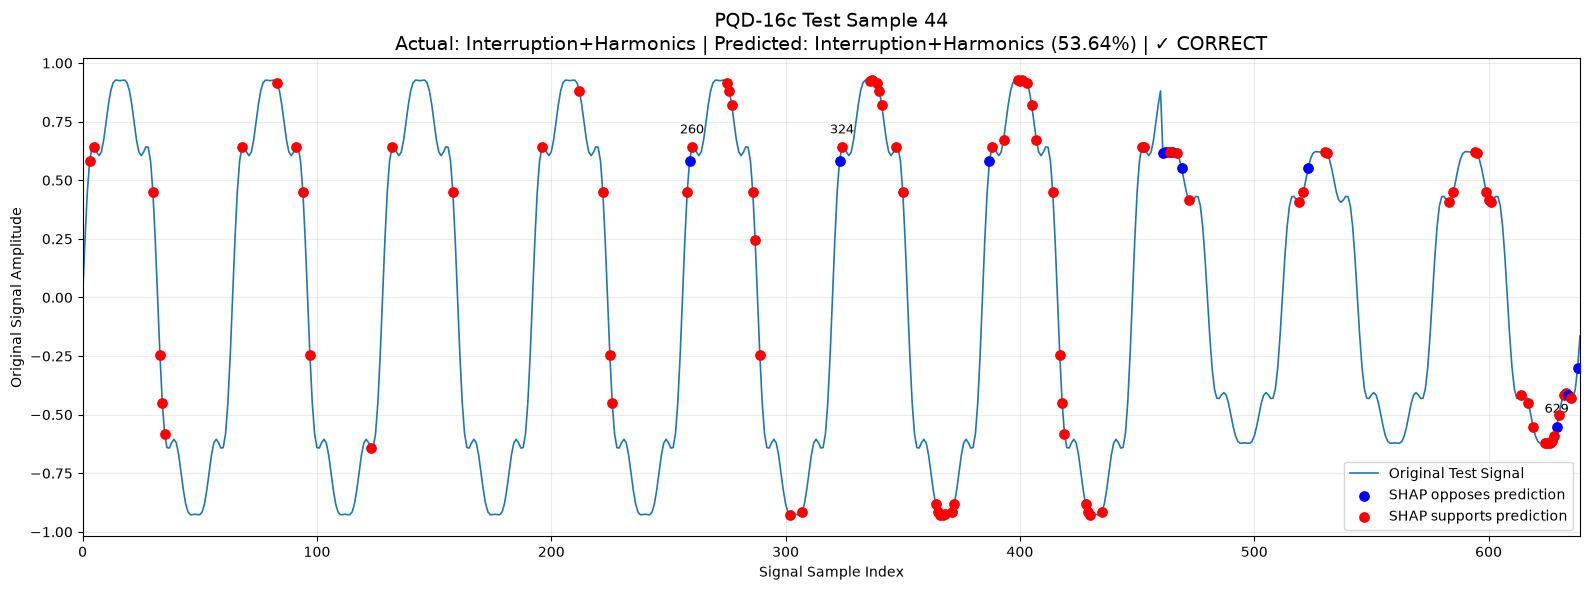

In [25]:
# ============================================================
# PQD-16c SHAP NOTEBOOK
# CELL 2 — PREDICTION + SHAP + VISUALIZATION
#
# NOTE:
# Sample selection is handled by CELL 1.5.
# This cell uses the existing sample_idx.
# ============================================================


# ============================================================
# SELECT THE ALREADY-CHOSEN SAMPLE
# ============================================================

sample = TEST_SIGNALS[
    sample_idx:sample_idx + 1
].to(DEVICE)

raw_signal = TEST_RAW_SIGNALS[
    sample_idx
]

actual_class = str(
    TEST_LABELS[sample_idx]
)


# ============================================================
# MODEL PREDICTION
# ============================================================

model.eval()

with torch.no_grad():

    logits = model(sample)

    probabilities = torch.softmax(
        logits,
        dim=1
    )[0]

    predicted_idx = int(
        torch.argmax(probabilities).item()
    )

    confidence = float(
        probabilities[predicted_idx].item()
    )


predicted_class = CLASS_NAMES[
    predicted_idx
]

correct = (
    actual_class == predicted_class
)


# ============================================================
# PREDICTION RESULT
# ============================================================

print()
print("=" * 70)
print("PREDICTION RESULT")
print("=" * 70)

print(
    f"Sample number : {sample_idx + 1}"
)

print(
    f"Actual class  : {actual_class}"
)

print(
    f"Predicted     : {predicted_class}"
)

print(
    f"Confidence    : {confidence:.2%}"
)

print(
    f"Result        : "
    f"{'✓ CORRECT' if correct else '✗ INCORRECT'}"
)

print("=" * 70)


# ============================================================
# CLASS PROBABILITIES
# ============================================================

print()
print("CLASS PROBABILITIES")
print("-" * 70)

for i in torch.argsort(
    probabilities,
    descending=True
):

    i = int(i)

    print(
        f"{i:<3} "
        f"{CLASS_NAMES[i]:<30} "
        f"{probabilities[i].item():>7.2%}"
    )


# ============================================================
# CREATE SHAP BACKGROUND
# ============================================================

print()
print("Creating SHAP background...")

TRAIN_PATH = DATA_DIR / "train.csv"

(
    TRAIN_SIGNALS,
    _,
    _,
    _
) = shap_lib.load_dataset(
    pd,
    TRAIN_PATH,
    TRAIN_MEAN,
    TRAIN_STD
)

BACKGROUND_SIZE = min(
    32,
    len(TRAIN_SIGNALS)
)

rng = np.random.default_rng(42)

background_indices = rng.choice(
    len(TRAIN_SIGNALS),
    size=BACKGROUND_SIZE,
    replace=False
)

background = TRAIN_SIGNALS[
    background_indices
].to(DEVICE)


# ============================================================
# CREATE SHAP EXPLAINER
# ============================================================

print(
    "Creating SHAP explainer..."
)

shap = shap_lib.import_runtime()[3]

explainer = shap.GradientExplainer(
    model,
    background
)


# ============================================================
# CALCULATE SHAP VALUES
# ============================================================

print(
    "Calculating SHAP values..."
)

raw_shap_values = explainer.shap_values(
    sample,
    nsamples=200
)


# ============================================================
# EXTRACT PREDICTED-CLASS SHAP VALUES
# ============================================================

shap_values = (
    shap_lib.select_class_shap_values(
        raw_shap_values,
        predicted_idx,
        NUM_CLASSES,
        len(raw_signal)
    )
)

shap_values = np.asarray(
    shap_values,
    dtype=np.float64
).reshape(-1)


if len(shap_values) != len(raw_signal):

    raise RuntimeError(
        f"SHAP/features mismatch: "
        f"{len(shap_values)} SHAP values vs "
        f"{len(raw_signal)} signal points."
    )


# ============================================================
# FIND MOST INFLUENTIAL POINTS
# ============================================================

TOP_K = 100

top_indices = np.argsort(
    np.abs(shap_values)
)[::-1][:TOP_K]


# ============================================================
# SHAP INTERPRETATION
# ============================================================

positive_total = float(
    shap_values[
        shap_values > 0
    ].sum()
)

negative_total = float(
    shap_values[
        shap_values < 0
    ].sum()
)

absolute_total = float(
    np.abs(shap_values).sum()
)


print()
print("=" * 70)
print("SHAP EXPLANATION")
print("=" * 70)

print(
    f"\nThe model predicted "
    f"'{predicted_class}' "
    f"with {confidence:.2%} confidence."
)

print(
    "\nHow to read SHAP:"
)

print(
    "  Positive SHAP → supports the predicted class"
)

print(
    "  Negative SHAP → opposes the predicted class"
)

print(
    "  Larger |SHAP| → stronger influence"
)

print()
print("TOP INFLUENTIAL SIGNAL POINTS")
print("-" * 70)

for rank, idx in enumerate(
    top_indices,
    1
):

    value = float(
        shap_values[idx]
    )

    direction = (
        "SUPPORTS prediction"
        if value > 0
        else
        "OPPOSES prediction"
    )

    print(
        f"{rank:>2}. "
        f"Point {idx:>3} | "
        f"Signal = {raw_signal[idx]:>20.4f} | "
        f"SHAP = {value:+.6f} | "
        f"{direction}"
    )


print()
print("ATTRIBUTION SUMMARY")
print("-" * 70)

print(
    f"Positive contribution : "
    f"{positive_total:+.6f}"
)

print(
    f"Negative contribution : "
    f"{negative_total:+.6f}"
)

print(
    f"Total |SHAP|          : "
    f"{absolute_total:.6f}"
)

if positive_total > abs(
    negative_total
):

    print(
        "\nInterpretation: "
        "Overall SHAP evidence supports "
        "the predicted class."
    )

else:

    print(
        "\nInterpretation: "
        "There is substantial SHAP evidence "
        "opposing the predicted class."
    )

print("=" * 70)


# ============================================================
# VISUALIZATION
# ============================================================

fig, ax = plt.subplots(
    figsize=(16, 6)
)

x = np.arange(
    len(raw_signal)
)


# ============================================================
# ORIGINAL SIGNAL
# ============================================================

ax.plot(
    x,
    raw_signal,
    linewidth=1.2,
    label="Original Test Signal",
    zorder=2
)


# ============================================================
# SHAP POINTS
# ============================================================

support_label_added = False
oppose_label_added = False

for idx in top_indices:

    value = float(
        shap_values[idx]
    )

    if value > 0:

        ax.scatter(
            idx,
            raw_signal[idx],
            color="red",
            s=45,
            zorder=5,
            label=(
                "SHAP supports prediction"
                if not support_label_added
                else None
            )
        )

        support_label_added = True

    else:

        ax.scatter(
            idx,
            raw_signal[idx],
            color="blue",
            s=45,
            zorder=5,
            label=(
                "SHAP opposes prediction"
                if not oppose_label_added
                else None
            )
        )

        oppose_label_added = True


# ============================================================
# LABEL STRONGEST SHAP POINTS
# ============================================================

LABEL_K = min(
    3,
    len(top_indices)
)

for idx in top_indices[:LABEL_K]:

    ax.annotate(
        str(idx),
        (
            idx,
            raw_signal[idx]
        ),
        xytext=(
            0,
            10
        ),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )


# ============================================================
# TITLE
# ============================================================

result = (
    "✓ CORRECT"
    if correct
    else
    "✗ INCORRECT"
)

ax.set_title(
    f"PQD-16c Test Sample {sample_idx + 1}\n"
    f"Actual: {actual_class} | "
    f"Predicted: {predicted_class} "
    f"({confidence:.2%}) | "
    f"{result}",
    fontsize=14
)


# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "Signal Sample Index"
)

ax.set_ylabel(
    "Original Signal Amplitude"
)

ax.grid(
    alpha=0.25
)

ax.legend(
    loc="lower right"
)

ax.set_xlim(
    0,
    len(raw_signal) - 1
)


# ============================================================
# DISPLAY
# ============================================================

plt.tight_layout()

plt.show()

# Attention based XAI


ATTENTION ANALYSIS
Sample number : 44
Actual class  : Interruption+Harmonics
Predicted     : Interruption+Harmonics
Confidence    : 53.64%
Result        : ✓ CORRECT

Extracting attention weights...

ATTENTION INFORMATION
BiLSTM sequence length : 80
Original signal length : 640
Attention sum          : 1.000000
Maximum attention      : 0.033270
Mean attention         : 0.012500

TOP 20 MOST ATTENDED SIGNAL POINTS
----------------------------------------------------------------------
 1. Point 397 | Signal =    0.9156 | Attention = 0.033231
 2. Point 396 | Signal =    0.8812 | Attention = 0.033222
 3. Point 398 | Signal =    0.9271 | Attention = 0.033173
 4. Point 399 | Signal =    0.9265 | Attention = 0.033115
 5. Point 395 | Signal =    0.8214 | Attention = 0.033084
 6. Point 400 | Signal =    0.9247 | Attention = 0.033056
 7. Point 401 | Signal =    0.9265 | Attention = 0.032998
 8. Point 394 | Signal =    0.7453 | Attention = 0.032945
 9. Point 402 | Signal =    0.9271 | Attention =

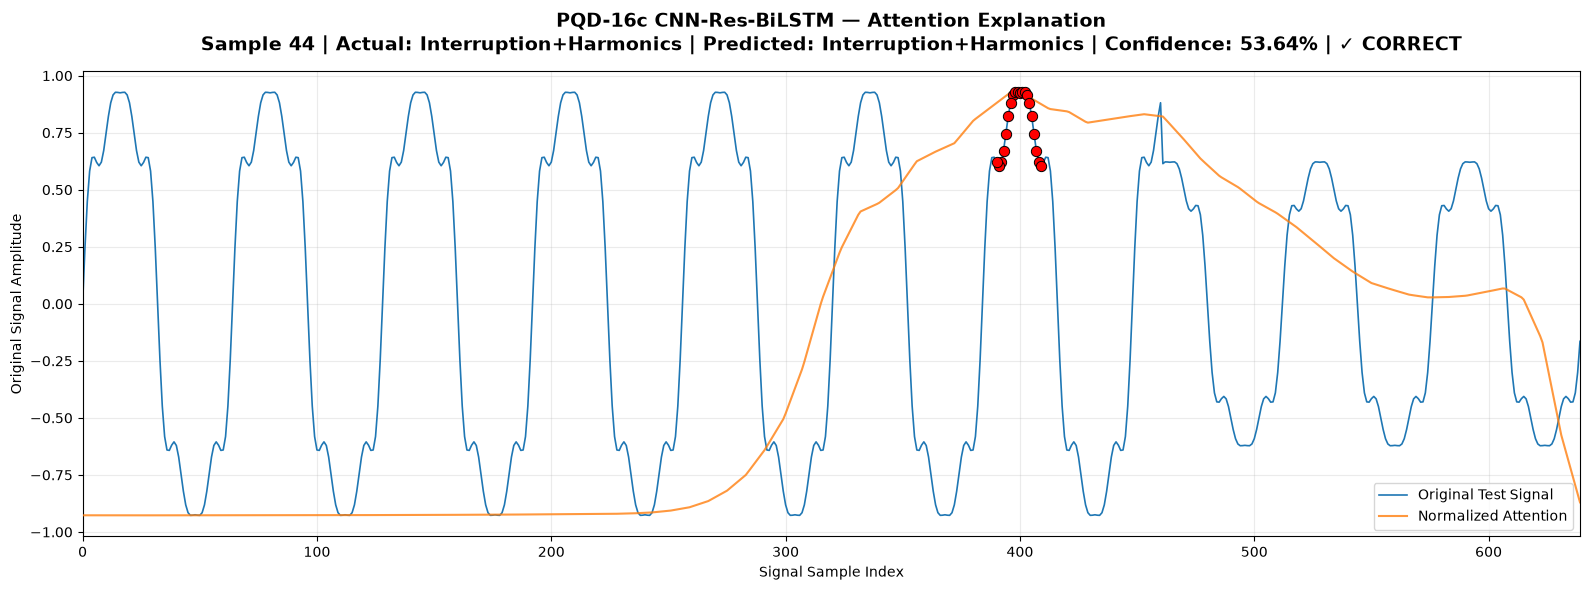

In [26]:
# ============================================================
# PQD-16c ATTENTION NOTEBOOK
# CELL 3 — ATTENTION ANALYSIS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

import attention_cnn_bilstm as attention_lib
import shap_cnn_bilstm as shap_lib


# ============================================================
# BUILD ATTENTION MODEL
# ============================================================

nn = shap_lib.import_runtime()[0]

attention_model = shap_lib.build_model(
    nn,
    NUM_CLASSES
).to(DEVICE)

attention_model.load_state_dict(
    checkpoint["model_state_dict"]
)

attention_model.eval()


# ============================================================
# USE SAMPLE SELECTED IN SAMPLE-SELECTION CELL
# ============================================================

# sample_idx is already defined before Cell 2 and Cell 3.
#
# Cell 2 already created:
#
#     sample
#     raw_signal
#     actual_class
#     predicted_class
#     confidence
#     correct
#
# Therefore Cell 3 simply reuses them.


# ============================================================
# ATTENTION ANALYSIS HEADER
# ============================================================

print()
print("=" * 70)
print("ATTENTION ANALYSIS")
print("=" * 70)

print(
    f"Sample number : {sample_idx + 1}"
)

print(
    f"Actual class  : {actual_class}"
)

print(
    f"Predicted     : {predicted_class}"
)

print(
    f"Confidence    : {confidence:.2%}"
)

print(
    f"Result        : "
    f"{'✓ CORRECT' if correct else '✗ INCORRECT'}"
)

print("=" * 70)


# ============================================================
# EXTRACT ATTENTION
# ============================================================

print("\nExtracting attention weights...")

TOP_K = 20

explanation = attention_lib.explain_attention(
    attention_model,
    sample,
    signal_length=len(raw_signal),
    top_k=TOP_K
)


# ============================================================
# GET ATTENTION DATA
# ============================================================

raw_attention = np.asarray(
    explanation["raw_attention"],
    dtype=np.float64
).reshape(-1)

interpolated_attention = np.asarray(
    explanation["interpolated_attention"],
    dtype=np.float64
).reshape(-1)

normalized_attention = np.asarray(
    explanation["normalized_attention"],
    dtype=np.float64
).reshape(-1)

top_indices = np.asarray(
    explanation["top_indices"],
    dtype=int
)


# ============================================================
# VALIDATE ATTENTION
# ============================================================

if len(interpolated_attention) != len(raw_signal):

    raise RuntimeError(
        f"Attention/signal mismatch: "
        f"{len(interpolated_attention)} attention values "
        f"vs {len(raw_signal)} signal points."
    )

if len(top_indices) == 0:

    raise RuntimeError(
        "No attention points were returned."
    )


# ============================================================
# ATTENTION INFORMATION
# ============================================================

print()
print("=" * 70)
print("ATTENTION INFORMATION")
print("=" * 70)

print(
    f"BiLSTM sequence length : "
    f"{len(raw_attention)}"
)

print(
    f"Original signal length : "
    f"{len(raw_signal)}"
)

print(
    f"Attention sum          : "
    f"{raw_attention.sum():.6f}"
)

print(
    f"Maximum attention      : "
    f"{raw_attention.max():.6f}"
)

print(
    f"Mean attention         : "
    f"{raw_attention.mean():.6f}"
)

print("=" * 70)


# ============================================================
# TOP k ATTENTION POINTS
# ============================================================

print()
print(f"TOP {TOP_K} MOST ATTENDED SIGNAL POINTS")
print("-" * 70)

for rank, idx in enumerate(
    top_indices,
    1
):

    idx = int(idx)

    print(
        f"{rank:>2}. "
        f"Point {idx:>3} | "
        f"Signal = {raw_signal[idx]:>9.4f} | "
        f"Attention = "
        f"{interpolated_attention[idx]:.6f}"
    )

print("=" * 70)


# ============================================================
# ATTENTION INTERPRETATION
# ============================================================

strongest_idx = int(
    top_indices[0]
)

total_attention = float(
    interpolated_attention.sum()
)

if total_attention > 0:

    top_attention_mass = float(
        interpolated_attention[
            top_indices
        ].sum()
        / total_attention
    )

else:

    top_attention_mass = 0.0


print()
print("INTERPRETATION")
print("-" * 70)

print(
    f"The model placed its strongest attention "
    f"around signal point {strongest_idx}."
)

print(
    f"The top {TOP_K} attended points contain "
    f"{top_attention_mass:.2%} of the "
    f"total interpolated attention."
)

print(
    f"The predicted class is "
    f"'{predicted_class}' "
    f"with {confidence:.2%} confidence."
)

print(
    "Higher attention means the learned attention "
    "mechanism assigned more weight to that temporal "
    "representation."
)

print(
    "Attention indicates model focus; it does not "
    "by itself prove causal importance."
)

print("=" * 70)


# ============================================================
# VISUALIZATION
# ============================================================

fig, ax = plt.subplots(
    figsize=(16, 6)
)

x = np.arange(
    len(raw_signal)
)


# ============================================================
# ORIGINAL SIGNAL
# ============================================================

ax.plot(
    x,
    raw_signal,
    linewidth=1.2,
    label="Original Test Signal",
    zorder=2
)


# ============================================================
# ATTENTION — NORMALIZED TO SIGNAL RANGE
# ============================================================

signal_min = float(
    raw_signal.min()
)

signal_max = float(
    raw_signal.max()
)

signal_range = (
    signal_max - signal_min
)

attention_scaled = (
    signal_min
    + normalized_attention * signal_range
)


ax.plot(
    x,
    attention_scaled,
    linewidth=1.5,
    alpha=0.8,
    label="Normalized Attention",
    zorder=3
)


# ============================================================
# TOP 8 ATTENTION POINTS
# ============================================================

for idx in top_indices:

    idx = int(idx)

    ax.scatter(
        idx,
        raw_signal[idx],
        color="red",
        s=55,
        edgecolors="black",
        linewidths=0.7,
        zorder=5
    )


# ============================================================
# TITLE
# ============================================================

result = (
    "✓ CORRECT"
    if correct
    else
    "✗ INCORRECT"
)

ax.set_title(
    f"PQD-16c CNN-Res-BiLSTM — Attention Explanation\n"
    f"Sample {sample_idx + 1} | "
    f"Actual: {actual_class} | "
    f"Predicted: {predicted_class} | "
    f"Confidence: {confidence:.2%} | "
    f"{result}",
    fontsize=14,
    fontweight="bold",
    pad=15
)


# ============================================================
# AXES
# ============================================================

ax.set_xlabel(
    "Signal Sample Index"
)

ax.set_ylabel(
    "Original Signal Amplitude"
)

ax.set_xlim(
    0,
    len(raw_signal) - 1
)

ax.grid(
    alpha=0.25
)

ax.legend(
    loc="lower right"
)


# ============================================================
# DISPLAY
# ============================================================

plt.tight_layout()
plt.show()